In [1]:
import os
import tarfile
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
import optuna

# Hide Optuna verbosity
optuna.logging.set_verbosity(optuna.logging.WARNING)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
PLANT_CLASSES = [
    54, 62, 70, 82, 92,  # Flowers
    0, 51, 53, 57, 83,   # Fruit & Veggies
    47, 52, 56, 59, 96   # Trees
]
CLASS_MAP = {original_id: new_id for new_id, original_id in enumerate(PLANT_CLASSES)}
PLANT_CLASS_NAMES = [
    'orchid', 'poppy', 'rose', 'sunflower', 'tulip', 
    'apple', 'mushroom', 'orange', 'pear', 'sweet_pepper',
    'maple_tree', 'oak_tree', 'palm_tree', 'pine_tree', 'willow_tree'
]

class CIFAR100SubsetDataset(Dataset):
    def __init__(self, tar_path, allowed_classes, class_map, train=True, transform=None):
        self.transform = transform
        
        with tarfile.open(tar_path, "r:gz") as tar:
            target_file = 'cifar-100-python/train' if train else 'cifar-100-python/test'
            data_dict = pickle.load(tar.extractfile(target_file), encoding='bytes')
            
        raw_data = data_dict[b'data'].reshape((-1, 3, 32, 32)).transpose(0, 2, 3, 1)
        raw_targets = np.array(data_dict[b'fine_labels'])
        
        mask = np.isin(raw_targets, allowed_classes)
        self.data = raw_data[mask]
        self.targets = np.array([class_map[t] for t in raw_targets[mask]])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, target = self.data[idx], self.targets[idx]
        if self.transform:
            img = self.transform(img)
        return img, target

# Transforms
transform_train = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761)),
])
transform_val = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761)),
])

# Create DataLoaders
tar_path = "data/cifar-100-python.tar.gz"
full_train = CIFAR100SubsetDataset(tar_path, PLANT_CLASSES, CLASS_MAP, train=True)

train_idx, val_idx = train_test_split(
    np.arange(len(full_train.targets)), test_size=0.2, stratify=full_train.targets, random_state=42
)

train_data = Subset(CIFAR100SubsetDataset(tar_path, PLANT_CLASSES, CLASS_MAP, True, transform_train), train_idx)
val_data = Subset(CIFAR100SubsetDataset(tar_path, PLANT_CLASSES, CLASS_MAP, True, transform_val), val_idx)
test_data = CIFAR100SubsetDataset(tar_path, PLANT_CLASSES, CLASS_MAP, False, transform_val)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False, pin_memory=True)

In [3]:
# Model Architecture
class Simple2DCNN(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(True), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(True), nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate), nn.Linear(256 * 4 * 4, 512), nn.ReLU(True),
            nn.Dropout(dropout_rate), nn.Linear(512, 15)
        )
    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

# Evaluation Helper
def evaluate_model(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            total += targets.size(0)
            correct += preds.eq(targets).sum().item()
    return running_loss / total, 100.0 * correct / total

# Training Loop Helper
def train_model(model, train_ld, val_ld, optimizer, criterion, epochs=50, patience=10, save_name="best.pt"):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_loss, patience_counter = float('inf'), 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, targets in train_ld:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            total += targets.size(0)
            correct += preds.eq(targets).sum().item()
            
        train_loss, train_acc = running_loss / total, 100.0 * correct / total
        val_loss, val_acc = evaluate_model(model, val_ld, criterion)
        
        for k, v in zip(history.keys(), [train_loss, val_loss, train_acc, val_acc]):
            history[k].append(v)
            
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:02d}/{epochs}] Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.2f}%")
            
        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), save_name)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}.")
                break
                
    model.load_state_dict(torch.load(save_name))
    return history, model

In [4]:
# Plotting Helper
def plot_curves(history, title_prefix=""):
    dummy_acc = 100.0 / 15.0
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.plot(history['train_loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss', linestyle='--')
    ax1.set_title(f'{title_prefix} Loss')
    ax1.legend(); ax1.grid(True, linestyle=':', alpha=0.6)
    
    ax2.plot(history['train_acc'], label='Train Acc')
    ax2.plot(history['val_acc'], label='Val Acc', linestyle='--')
    ax2.axhline(y=dummy_acc, color='r', linestyle=':', label=f'Baseline ({dummy_acc:.1f}%)')
    ax2.set_title(f'{title_prefix} Accuracy')
    ax2.legend(); ax2.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout(); plt.show()

--- Training Pre-Tune Model ---
Epoch [01/50] Train Loss: 2.1651 | Val Acc: 42.00%
Epoch [05/50] Train Loss: 1.5296 | Val Acc: 54.67%
Epoch [10/50] Train Loss: 1.3490 | Val Acc: 57.40%
Epoch [15/50] Train Loss: 1.2320 | Val Acc: 60.33%
Epoch [20/50] Train Loss: 1.1236 | Val Acc: 60.60%
Epoch [25/50] Train Loss: 1.0497 | Val Acc: 64.27%
Epoch [30/50] Train Loss: 0.9823 | Val Acc: 66.67%
Epoch [35/50] Train Loss: 0.9208 | Val Acc: 68.00%
Epoch [40/50] Train Loss: 0.8534 | Val Acc: 70.80%
Epoch [45/50] Train Loss: 0.8015 | Val Acc: 69.33%
Epoch [50/50] Train Loss: 0.7740 | Val Acc: 71.27%

Final Pre-Tune Test Acc: 69.93%


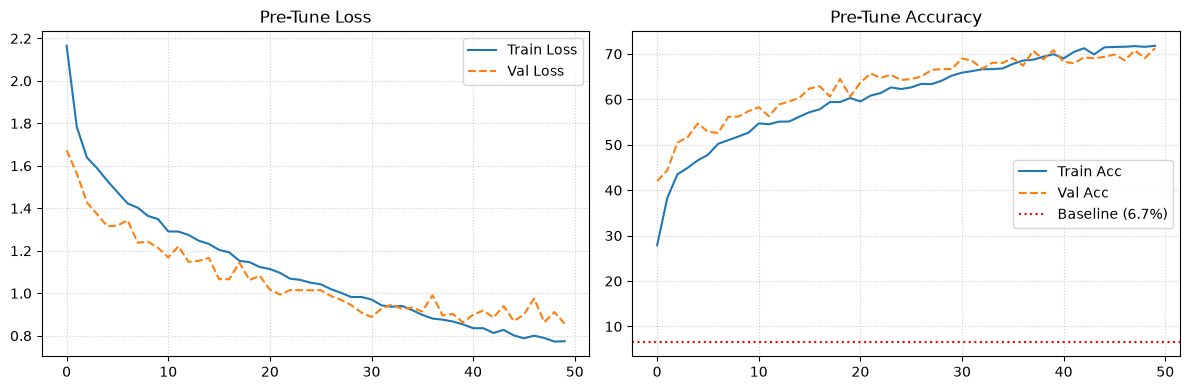

In [5]:
print("--- Training Pre-Tune Model ---")
baseline_model = Simple2DCNN(dropout_rate=0.5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(baseline_model.parameters(), lr=0.001, weight_decay=1e-4)

base_history, baseline_model = train_model(
    baseline_model, train_loader, val_loader, optimizer, criterion, 
    epochs=50, patience=10, save_name="baseline.pt"
)

pre_tune_test_loss, pre_tune_test_acc = evaluate_model(baseline_model, test_loader, criterion)
print(f"\nFinal Pre-Tune Test Acc: {pre_tune_test_acc:.2f}%")
plot_curves(base_history, "Pre-Tune")

In [ ]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.2, 0.6, step=0.1)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ["AdamW", "SGD"])
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    
    opt_train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    opt_val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
    
    model = PlantCNN(dropout_rate).to(device)
    crit = nn.CrossEntropyLoss()
    
    if optimizer_name == "AdamW":
        opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    # 10 epochs to allow pruning mechanics to kick in after warmup
    for epoch in range(10):
        model.train()
        for inputs, targets in opt_train_loader:
            opt.zero_grad()
            crit(model(inputs.to(device)), targets.to(device)).backward()
            opt.step()

        # Evaluate validation loss at the end of each epoch
        val_loss, val_acc = evaluate_model(model, opt_val_loader, crit)
        
        # Report intermediate validation loss to Optuna
        trial.report(val_loss, epoch)

        # Cut the trial short if it's performing worse than the median of prior runs
        if trial.should_prune():
            raise optuna.TrialPruned()

    # Objective is now returning validation loss
    return val_loss

In [ ]:
study = optuna.create_study(
    direction="minimize", 
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=2)
)

study.optimize(objective, n_trials=30)

best_params = study.best_trial.params
print("Best Optuna Parameters:", best_params)
print(f"Best Validation Loss: {study.best_value:.4f}")

Best Optuna Parameters: {'lr': 0.000213887535816911, 'dropout_rate': 0.30000000000000004, 'weight_decay': 0.005728791904416435, 'optimizer': 'AdamW', 'batch_size': 32}


In [9]:
def plot_comparison_curves(pre_history, tuned_history):
    dummy_acc = 100.0 / 15.0  # 6.67%
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # ---------------------------------------------------------
    # 1. Loss Comparison Plot
    # ---------------------------------------------------------
    # Pre-Tuned Model (Blue Theme)
    ax1.plot(pre_history['train_loss'], color='#1f77b4', linestyle='-', linewidth=2, label='Pre-Tune Train Loss')
    ax1.plot(pre_history['val_loss'], color='#1f77b4', linestyle='--', linewidth=2, label='Pre-Tune Val Loss')
    
    # Tuned Model (Red Theme)
    ax1.plot(tuned_history['train_loss'], color='#d62728', linestyle='-', linewidth=2, label='Tuned Train Loss')
    ax1.plot(tuned_history['val_loss'], color='#d62728', linestyle='--', linewidth=2, label='Tuned Val Loss')
    
    ax1.set_title('Loss Comparison: Pre-Tune vs. Tuned', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epochs', fontsize=11)
    ax1.set_ylabel('Loss (Cross-Entropy)', fontsize=11)
    ax1.legend(fontsize=10)
    ax1.grid(True, linestyle=':', alpha=0.6)
    
    # ---------------------------------------------------------
    # 2. Accuracy Comparison Plot
    # ---------------------------------------------------------
    # Pre-Tuned Model (Blue Theme)
    ax2.plot(pre_history['train_acc'], color='#1f77b4', linestyle='-', linewidth=2, label='Pre-Tune Train Acc')
    ax2.plot(pre_history['val_acc'], color='#1f77b4', linestyle='--', linewidth=2, label='Pre-Tune Val Acc')
    
    # Tuned Model (Red Theme)
    ax2.plot(tuned_history['train_acc'], color='#d62728', linestyle='-', linewidth=2, label='Tuned Train Acc')
    ax2.plot(tuned_history['val_acc'], color='#d62728', linestyle='--', linewidth=2, label='Tuned Val Acc')
    
    # Dummy Baseline Threshold
    ax2.axhline(y=dummy_acc, color='gray', linestyle=':', linewidth=1.5, label=f'Baseline Acc ({dummy_acc:.2f}%)')
    
    ax2.set_title('Accuracy Comparison: Pre-Tune vs. Tuned', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epochs', fontsize=11)
    ax2.set_ylabel('Accuracy (%)', fontsize=11)
    ax2.legend(fontsize=10)
    ax2.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [11]:
print("\n--- Training Tuned Model ---")
tuned_model = Simple2DCNN(dropout_rate=best_params['dropout_rate']).to(device)
criterion = nn.CrossEntropyLoss()

if best_params['optimizer'] == 'AdamW':
    optimizer = optim.AdamW(
        tuned_model.parameters(), 
        lr=best_params['lr'], 
        weight_decay=best_params['weight_decay']
    )
else:
    optimizer = optim.SGD(
        tuned_model.parameters(), 
        lr=best_params['lr'], 
        momentum=0.9, 
        weight_decay=best_params['weight_decay']
    )

tuned_history, tuned_model = train_model(
    tuned_model, train_loader, val_loader, optimizer, criterion, 
    epochs=50, patience=10, save_name="tuned.pt"
)

test_loss, test_acc = evaluate_model(tuned_model, test_loader, criterion)


--- Training Tuned Model ---
Epoch [01/50] Train Loss: 2.0204 | Val Acc: 44.73%
Epoch [05/50] Train Loss: 1.3564 | Val Acc: 56.00%
Epoch [10/50] Train Loss: 1.1211 | Val Acc: 62.13%
Epoch [15/50] Train Loss: 0.9854 | Val Acc: 66.33%
Epoch [20/50] Train Loss: 0.9139 | Val Acc: 65.60%
Epoch [25/50] Train Loss: 0.8176 | Val Acc: 66.40%
Epoch [30/50] Train Loss: 0.7572 | Val Acc: 70.47%
Epoch [35/50] Train Loss: 0.7046 | Val Acc: 68.93%
Epoch [40/50] Train Loss: 0.6334 | Val Acc: 67.60%
Epoch [45/50] Train Loss: 0.5931 | Val Acc: 70.60%
Early stopping at epoch 47.


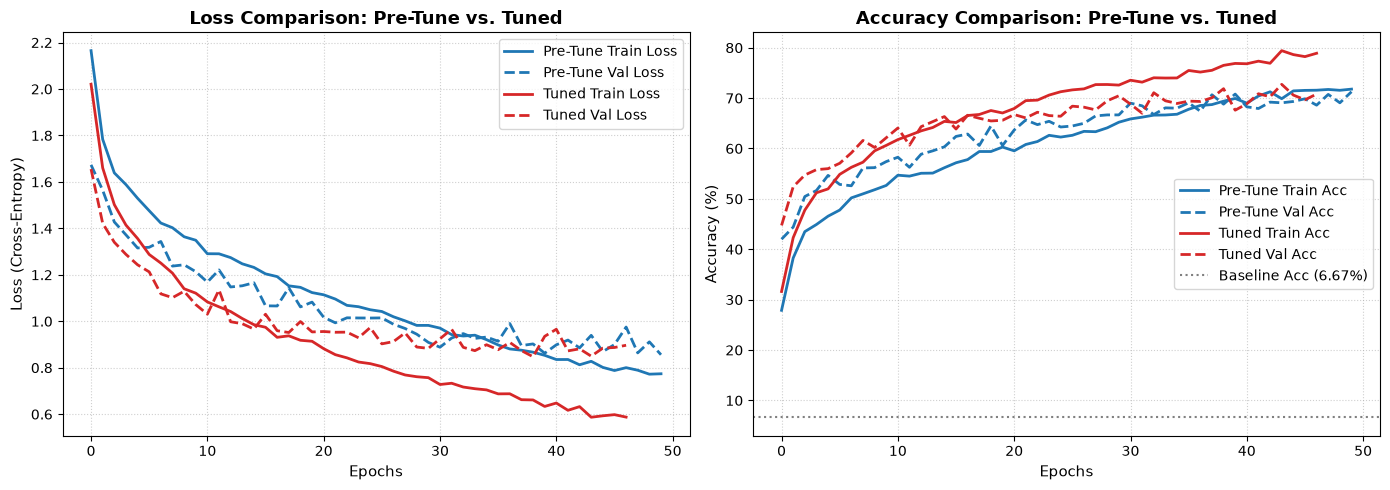


--- Model Performance Comparison ---
Dummy Baseline Accuracy: 6.67%
Before Tuning Test Acc: 69.93% (Loss: 0.8715)
After Tuning Test Acc: 71.00% (Loss: 0.8496)
Accuracy Difference: 1.07%



In [12]:
# Plot overlaid comparison (Blue = Pre-Tune, Red = Tuned)
plot_comparison_curves(base_history, tuned_history)

print("\n--- Model Performance Comparison ---")
print(f"Dummy Baseline Accuracy: {100.0/15.0:.2f}%") 
print(f"Before Tuning Test Acc: {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
print(f"After Tuning Test Acc: {test_acc:.2f}% (Loss: {test_loss:.4f})")
print(f"Accuracy Difference: {test_acc - pre_tune_test_acc:.2f}%\n")